# Training a universal perturbation on a tiny VLM (SmolVLM-256M)

Extension of the replication notebook. Same data (ImageNetV2 matched-frequency), same seed and split logic, same ℓ∞ budget ξ = 10/255. What changes:

| | Replication | This notebook |
|---|---|---|
| Target | GoogLeNet classifier | Vision encoder of **SmolVLM-256M-Instruct** (SigLIP-B/16, 93M) |
| Input | 224 × 224 | 512 × 512, one tile (no image splitting) |
| Inner step | DeepFool (needs labels) | Gradient step on an **embedding loss** (no labels) |
| Success measure | Label flip | Visual tokens change (cosine) **and** the caption changes |

**Success criterion:** the universal perturbation must clearly beat random noise of the same budget on both measures.

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. Expected time: roughly 15–25 min.

**Outputs:** the perturbation `uap_smolvlm256m_linf10.npy`, the results file `uap_training_results.json` and example figures, all saved to Drive. The key printouts are the sanity check (section 6), the training log (section 7) and the results table with example captions (section 8).

## 1. Configuration

In [1]:
# ===================== CONFIG =====================
MODEL_ID   = "HuggingFaceTB/SmolVLM-256M-Instruct"
IMG_SIZE   = 512                 # SmolVLM-256M's vision tile size

N_BUILD    = 500                 # images used to compute v   (first 500 of the replication's X)
N_EVAL     = 500                 # held-out images for evaluation
N_CAPTION  = 200                 # of the eval images, how many get captioned (generation is the slow part)

NORM_XI    = 10/255              # l_inf budget, same as the replication (images in [0,1])
EPOCHS     = 10                  # passes over the build set
BATCH      = 8
LR         = 1/255               # Adam step on v (as in VEV-UAP)

TAU        = [0.9, 0.8]          # visual-token cosine thresholds for the "embedding fooling rate"
CAPTION_SIM_CHANGED = 0.5        # caption counts as "changed" if text similarity < this
PROMPT     = "Describe this image in one sentence."
MAX_NEW_TOKENS = 40

USE_DRIVE  = True
REPL_DIR   = "/content/drive/MyDrive/uap_replication"   # where the replication saved its v (optional baseline)
SEED       = 0
# ==================================================

## 2. Setup

In [2]:
!pip -q install "transformers>=4.50" sentence-transformers
import os, time, json, glob, random, tarfile, zipfile, subprocess
from pathlib import Path
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm
import transformers
print("transformers", transformers.__version__, "| torch", torch.__version__)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
assert DEVICE == "cuda", "No GPU: Runtime -> Change runtime type -> T4 GPU"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/uap_smolvlm")
else:
    OUT_DIR = Path("/content/uap_smolvlm")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Outputs ->", OUT_DIR)

transformers 5.22.1 | torch 2.14.1+cu130
Device: cuda Tesla T4
Mounted at /content/drive
Outputs -> /content/drive/MyDrive/uap_smolvlm


## 3. Data (same ImageNetV2 download as the replication)

In [3]:
DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
TAR_NAME = "imagenetv2-matched-frequency.tar.gz"
URL = f"https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/{TAR_NAME}"

def extracted_dirs():
    return [d for d in DATA_DIR.glob("imagenetv2-*") if d.is_dir()]

if not extracted_dirs():
    tar_path = DATA_DIR / TAR_NAME
    if not tar_path.exists() or tar_path.stat().st_size < 1e9:
        !wget -q --show-progress -O {tar_path} {URL}
    if tarfile.is_tarfile(tar_path):
        with tarfile.open(tar_path, "r:*") as t: t.extractall(DATA_DIR)
    elif zipfile.is_zipfile(tar_path):
        with zipfile.ZipFile(tar_path) as z: z.extractall(DATA_DIR)
    else:
        raise RuntimeError("Download is not a tar or zip archive.")
    tar_path.unlink()

FILES = sorted(glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
print(len(FILES), "images found")   # expected: 10000

# Same permutation as the replication, so the build set is the first 500 images of its X
perm = np.random.RandomState(SEED).permutation(len(FILES))
files_build = [FILES[i] for i in perm[:N_BUILD]]
files_eval  = [FILES[i] for i in perm[N_BUILD:N_BUILD + N_EVAL]]

PREPROC = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE), transforms.PILToTensor()])
def load_uint8(files):
    return torch.stack([PREPROC(Image.open(f).convert("RGB")) for f in tqdm(files, desc="decoding")])

B_u8 = load_uint8(files_build)
E_u8 = load_uint8(files_eval)
print("build:", tuple(B_u8.shape), " eval:", tuple(E_u8.shape))

/content/data/image 100%[===================>]   1.18G  13.9MB/s    in 21s     


/tmp/ipykernel_510/2972835718.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tar_path, "r:*") as t: t.extractall(DATA_DIR)


10000 images found


decoding:   0%|          | 0/500 [00:00<?, ?it/s]

decoding:   0%|          | 0/500 [00:00<?, ?it/s]

build: (500, 3, 512, 512)  eval: (500, 3, 512, 512)


## 4. Load SmolVLM-256M

In [4]:
from transformers import AutoProcessor, AutoModelForImageTextToText

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE).eval()
for p in model.parameters(): p.requires_grad_(False)

# The vision encoder (SigLIP-B/16). Path checked against transformers' SmolVLM source.
VIS = model.model.vision_model
ip = processor.image_processor
MEAN = torch.tensor(ip.image_mean, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(ip.image_std,  device=DEVICE).view(1, 3, 1, 1)
print("image_mean", ip.image_mean, "image_std", ip.image_std, "| max_image_size", getattr(ip, "max_image_size", None))
print("Vision encoder params: %.1fM" % (sum(p.numel() for p in VIS.parameters()) / 1e6))

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

image_mean (0.5, 0.5, 0.5) image_std (0.5, 0.5, 0.5) | max_image_size {'longest_edge': 512}
Vision encoder params: 86.4M


## 5. Helpers: normalisation, visual tokens, batched captions

In [5]:
def norm(x01):                      # x in [0,1], (B,3,512,512) -> what the encoder expects
    return (x01 - MEAN) / STD

def visual_tokens(x01):             # (B, n_tokens, dim): the encoder's output, before the connector
    return VIS(pixel_values=norm(x01)).last_hidden_state

def token_cosine(a, b):             # mean over tokens of per-token cosine similarity -> (B,)
    return F.cosine_similarity(a, b, dim=-1).mean(dim=1)

# Build the text side once: same prompt and same number of image tokens for every image,
# so we can swap in our own pixel_values (clean or perturbed) and batch the generation.
messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}]
prompt_text = processor.apply_chat_template(messages, add_generation_prompt=True)
_dummy = Image.fromarray(np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8))
BASE = processor(text=prompt_text, images=[_dummy], do_image_splitting=False, return_tensors="pt")
print("pixel_values from processor:", tuple(BASE["pixel_values"].shape), "(expect (1, 1, 3, 512, 512))")
assert tuple(BASE["pixel_values"].shape[-3:]) == (3, IMG_SIZE, IMG_SIZE) and BASE["pixel_values"].shape[1] == 1, \
    "Processor did not give a single 512x512 tile: check the processor's image-splitting settings."

@torch.no_grad()
def caption(x01, bs=16):
    outs = []
    for i in range(0, len(x01), bs):
        xb = x01[i:i+bs]; B = len(xb)
        inp = {k: v.repeat(B, *[1] * (v.dim() - 1)).to(DEVICE) for k, v in BASE.items() if k != "pixel_values"}
        inp["pixel_values"] = norm(xb).unsqueeze(1)          # (B,1,3,H,W)
        gen = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += processor.batch_decode(gen[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

def to01(u8): return u8.to(DEVICE).float().div(255)

pixel_values from processor: (1, 1, 3, 512, 512) (expect (1, 1, 3, 512, 512))


## 6. Sanity check

In [6]:
# (a) Our normalisation must match the processor's on a real image
pil = Image.fromarray(B_u8[0].permute(1, 2, 0).numpy())
ref = processor(text=prompt_text, images=[pil], do_image_splitting=False, return_tensors="pt")["pixel_values"][0].to(DEVICE)
ours = norm(to01(B_u8[:1]))
print("max |ours - processor| =", (ours - ref).abs().max().item(), "(expect < 0.02; small differences come from resizing)")

# (b) Clean captions for 3 images, and the same images with mild random noise (should barely change)
x3 = to01(B_u8[:3])
noise = NORM_XI * torch.sign(torch.randn_like(x3[:1]))
for c0, c1 in zip(caption(x3), caption((x3 + noise).clamp(0, 1))):
    print("clean :", c0); print("noise :", c1); print()

max |ours - processor| = 0.054902076721191406 (expect < 0.02; small differences come from resizing)
clean : In this image there are two objects.
noise : In this image we can see two objects which are in white and purple color.

clean : In this image we can see a dog lying on the bed.
noise : In this image we can see a dog lying on the bed.

clean : In this image we can see a plant.
noise : In this image we can see a plant.



## 7. Compute the universal perturbation v (embedding loss, Adam, l∞ projection)

In [7]:
def train_uap(images_u8, xi=NORM_XI, epochs=EPOCHS, bs=BATCH, lr=LR, tag="uap"):
    v = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([v], lr=lr)
    hist, t0, n = [], time.time(), len(images_u8)
    for ep in range(epochs):
        losses = []
        for idx in torch.randperm(n).split(bs):
            x = to01(images_u8[idx])
            with torch.no_grad():
                z_clean = visual_tokens(x)
            z_adv = visual_tokens((x + v).clamp(0, 1))
            loss = token_cosine(z_clean, z_adv).mean()          # minimise similarity = push tokens away
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                v.clamp_(-xi, xi)                                 # projection onto the l_inf ball
            losses.append(loss.item())
        hist.append({"epoch": ep + 1, "mean_token_cos": float(np.mean(losses)), "minutes": (time.time() - t0) / 60})
        print(f"{tag} epoch {ep+1}: mean token cosine on build set = {hist[-1]['mean_token_cos']:.3f}  ({hist[-1]['minutes']:.1f} min)")
        torch.save(v.detach().cpu(), OUT_DIR / f"{tag}_ckpt.pt")
    return v.detach(), hist

v, hist = train_uap(B_u8)
np.save(OUT_DIR / "uap_smolvlm256m_linf10.npy", v.cpu().numpy())
print("||v||_inf =", v.abs().max().item() * 255, "/255")

uap epoch 1: mean token cosine on build set = 0.525  (1.9 min)
uap epoch 2: mean token cosine on build set = 0.140  (4.1 min)
uap epoch 3: mean token cosine on build set = 0.030  (6.3 min)
uap epoch 4: mean token cosine on build set = -0.024  (8.5 min)
uap epoch 5: mean token cosine on build set = -0.047  (10.7 min)
uap epoch 6: mean token cosine on build set = -0.070  (12.9 min)
uap epoch 7: mean token cosine on build set = -0.081  (15.1 min)
uap epoch 8: mean token cosine on build set = -0.072  (17.3 min)
uap epoch 9: mean token cosine on build set = -0.064  (19.6 min)
uap epoch 10: mean token cosine on build set = -0.081  (21.8 min)
||v||_inf = 10.000000353902578 /255


## 8. Evaluation on held-out images: universal v vs random noise (vs the replication's v)

In [8]:
@torch.no_grad()
def token_cos_all(images_u8, pert, bs=16):
    out = []
    for i in range(0, len(images_u8), bs):
        x = to01(images_u8[i:i+bs])
        xp = x if pert is None else (x + pert).clamp(0, 1)
        out.append(token_cosine(visual_tokens(x), visual_tokens(xp)).cpu())
    return torch.cat(out)

torch.manual_seed(SEED)
PERTS = {
    "universal v": v,
    "random ±ξ": NORM_XI * torch.sign(torch.randn_like(v)),
}
repl = Path(REPL_DIR) / "universal_googlenet_linf.npy"
if repl.exists():   # the replication's GoogLeNet v, upsampled 224 -> 512 (a baseline built for a different model)
    v_g = torch.from_numpy(np.load(repl)).to(DEVICE).float()
    PERTS["replication v (GoogLeNet, upsampled)"] = F.interpolate(v_g, size=IMG_SIZE, mode="bilinear", align_corners=False).clamp(-NORM_XI, NORM_XI)
else:
    print("Replication v not found at", repl, "- skipping that baseline")

from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
def text_sim(a, b):
    ea, eb = st.encode(a, convert_to_tensor=True, normalize_embeddings=True), st.encode(b, convert_to_tensor=True, normalize_embeddings=True)
    return (ea * eb).sum(-1).cpu()

caps_clean = caption(to01(E_u8[:N_CAPTION]))
RESULTS, CAPS = {"config": {k: globals()[k] for k in ["MODEL_ID","IMG_SIZE","N_BUILD","N_EVAL","N_CAPTION","NORM_XI","EPOCHS","BATCH","LR","TAU","CAPTION_SIM_CHANGED","PROMPT"]},
                 "train_history": hist, "eval": {}}, {"clean": caps_clean}
for name, pert in PERTS.items():
    cos = token_cos_all(E_u8, pert)
    caps = caption((to01(E_u8[:N_CAPTION]) + pert).clamp(0, 1))
    sim = text_sim(caps_clean, caps)
    CAPS[name] = caps
    RESULTS["eval"][name] = {
        "mean_token_cos": cos.mean().item(),
        **{f"emb_fool@{t}": (cos < t).float().mean().item() for t in TAU},
        "mean_caption_sim": sim.mean().item(),
        "caption_changed": (sim < CAPTION_SIM_CHANGED).float().mean().item(),
    }

print(f"Held-out: {N_EVAL} images for token metrics, {N_CAPTION} captioned | l_inf xi = {NORM_XI*255:.0f}/255\n")
hdr = f"{'perturbation':40s}{'token cos':>10s}" + "".join(f"{'fool@'+str(t):>11s}" for t in TAU) + f"{'cap sim':>9s}{'cap changed':>13s}"
print(hdr); print("-" * len(hdr))
for name, r in RESULTS["eval"].items():
    print(f"{name:40s}{r['mean_token_cos']:>10.3f}" + "".join(f"{r[f'emb_fool@{t}']:>11.1%}" for t in TAU)
          + f"{r['mean_caption_sim']:>9.3f}{r['caption_changed']:>13.1%}")

print("\nExample captions (first 8 eval images):")
for i in range(8):
    print(f"[{i}] clean     : {caps_clean[i]}")
    print(f"    universal : {CAPS['universal v'][i]}")
    print(f"    random    : {CAPS['random ±ξ'][i]}")

with open(OUT_DIR / "uap_training_results.json", "w") as f:
    json.dump({"results": RESULTS, "captions": CAPS}, f, indent=2, default=float)
print("\nSaved to", OUT_DIR / "uap_training_results.json")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Held-out: 500 images for token metrics, 200 captioned | l_inf xi = 10/255

perturbation                             token cos   fool@0.9   fool@0.8  cap sim  cap changed
----------------------------------------------------------------------------------------------
universal v                                 -0.051     100.0%     100.0%    0.171        91.0%
random ±ξ                                    0.846      91.6%      15.0%    0.866         5.0%
replication v (GoogLeNet, upsampled)         0.850      82.2%      18.0%    0.861         4.0%

Example captions (first 8 eval images):
[0] clean     : In this image we can see a bird on the branch of a tree.
    universal : 200000000000000000000000000000000000000
    random    : In this image we can see a bird on the branch of a tree.
[1] clean     : In this image we can see two dogs.
    universal : who said this on their wedding anniversary. who said this on their wedding anniversary. who said this on their wedding anniversary. who said

## 9. Visualise v and a few perturbed images

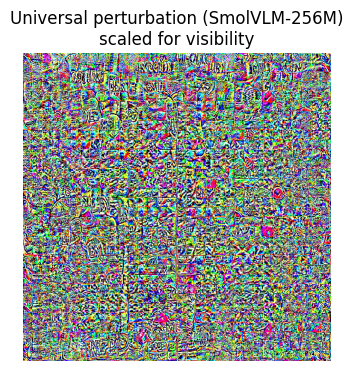

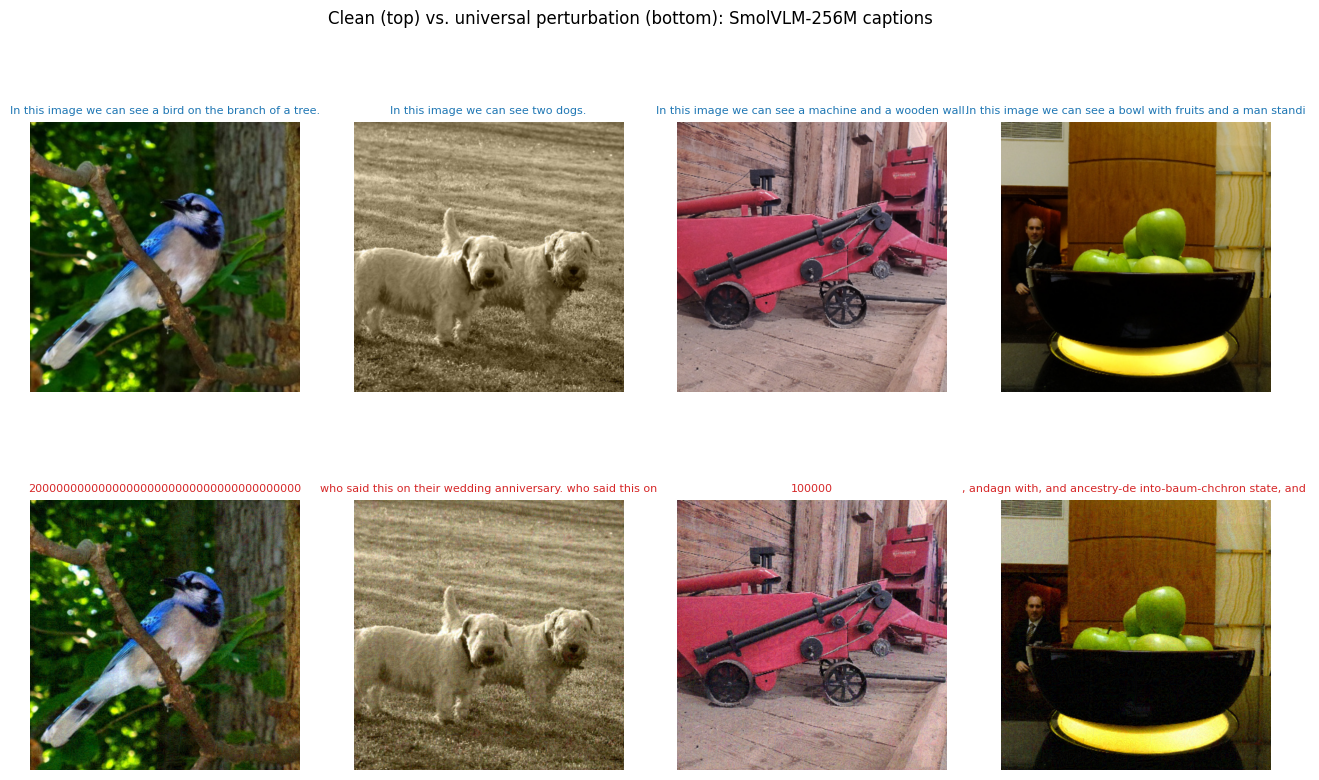

In [9]:
vv = v[0].permute(1, 2, 0).cpu().numpy()
plt.figure(figsize=(4, 4)); plt.imshow((vv - vv.min()) / (vv.max() - vv.min())); plt.axis("off")
plt.title("Universal perturbation (SmolVLM-256M)\nscaled for visibility")
plt.savefig(OUT_DIR / "uap_training_perturbation.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(16, 9))
for j in range(4):
    x = to01(E_u8[j:j+1]); xp = (x + v).clamp(0, 1)
    ax[0, j].imshow(x[0].permute(1, 2, 0).cpu()); ax[0, j].set_title(caps_clean[j][:60], fontsize=8, color="tab:blue")
    ax[1, j].imshow(xp[0].permute(1, 2, 0).cpu()); ax[1, j].set_title(CAPS["universal v"][j][:60], fontsize=8, color="tab:red")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.suptitle("Clean (top) vs. universal perturbation (bottom): SmolVLM-256M captions")
plt.savefig(OUT_DIR / "uap_training_examples.png", dpi=150, bbox_inches="tight"); plt.show()